# Atividade 15 — Relatório crítico: evidências numéricas

**Projeto:** Recomendação de treinos personalizados em academia · **Aluno:** Vinicius Casagrande · **Encontro 15**

Este notebook não treina um modelo novo. Ele mede o que o relatório crítico da Atividade 15 (`entregas/Atividade15_ViniciusCasagrande.md`) afirma, e responde com números as perguntas de defesa que ficaram abertas nos feedbacks das Atividades 11, 12 e 13:

| Pergunta deixada pela professora | Seção |
|---|---|
| 0,84 (balanced) contra 0,8267 (original), com desvio de 0,0291: a diferença é distinguível da variação entre folds? | 4 |
| O ganho de recall de D da rede neural (0,82 contra 0,73) é real ou ruído? | 5 |
| Por que a restrição física não piora o erro na hipertrofia? O ponto cego é do modelo ou da regra? | 6 |
| A rede reduziu os falsos negativos espalhados, mas não o ponto cego. O que isso diz sobre os dois tipos de erro? | 7 |
| Quantos alunos a regra de segurança moveria para o Treino D, e o que acontece com as outras classes? | 8 |
| Balancear as classes muda o motivo pelo qual a árvore usa idade? | 9 |

Além disso, a seção 9 faz a **auditoria de viés por subgrupo** e a **verificação de proxy** pedidas na Atividade 15.

O notebook usa o mesmo pré-processamento das Atividades 9 a 13 (one-hot sem `drop_first`, divisão 80/20 estratificada com `random_state=42`, validação cruzada `cv=5`).

In [1]:
import os
if not os.path.exists('dataset_academia_tratado.csv'):
    !git clone https://github.com/Vinicasagrande87/fundamentos_ia.git
    %cd fundamentos_ia

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import train_test_split, cross_validate, cross_val_predict, RepeatedStratifiedKFold
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, make_scorer, classification_report, confusion_matrix
from gerar_dataset import recomenda_treino

pd.set_option('display.width', 200)
print('scikit-learn', sklearn.__version__)

scikit-learn 1.9.1


## 1. Base, modelos e métricas

A métrica principal do projeto continua sendo o **recall de Treino D** (Atividade 10): Treino D é o treino adaptado (peso corporal) para quem não tem equipamento, tem restrição física e é iniciante, ou tem poucos dias. Deixar de recomendá-lo a quem precisa significa mandar essa pessoa para um treino mais intenso do que deveria.

Modelo final do projeto: **árvore de decisão com `max_depth=5` e `class_weight='balanced'`**, a candidata escolhida na Atividade 13.

In [3]:
df = pd.read_csv('dataset_academia_tratado.csv')
X = df.drop(columns=['aluno_id', 'treino_recomendado'])
y = df['treino_recomendado']
X = pd.get_dummies(X, columns=['objetivo', 'nivel_experiencia', 'restricao_fisica', 'equipamento_disponivel'], drop_first=False)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

CLASSES = ['Treino A', 'Treino B', 'Treino C', 'Treino D']
recall_D = lambda yt, yp: recall_score(yt, yp, labels=['Treino D'], average=None)[0]
precisao_D = lambda yt, yp: precision_score(yt, yp, labels=['Treino D'], average=None, zero_division=0)[0]
SCORING = {'acc': 'accuracy', 'f1': 'f1_macro', 'recD': make_scorer(recall_D)}

modelos = {
    'Baseline (most_frequent)': DummyClassifier(strategy='most_frequent'),
    'Arvore original (max_depth=5)': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Arvore balanced (modelo final)': DecisionTreeClassifier(max_depth=5, random_state=42, class_weight='balanced'),
}
print('Alunos:', len(df), '| features:', X.shape[1], '| teste:', len(X_test), '| Treino D no teste:', (y_test == 'Treino D').sum())

Alunos: 300 | features: 15 | teste: 60 | Treino D no teste: 18


## 2. Resultados principais: split único e validação cruzada, lado a lado com o baseline

In [4]:
linhas = []
for nome, m in modelos.items():
    m.fit(X_train, y_train)
    p = m.predict(X_test)
    cv = cross_validate(m, X, y, cv=5, scoring=SCORING)
    linhas.append({
        'modelo': nome,
        'acuracia_teste': accuracy_score(y_test, p),
        'recall_D_teste': recall_D(y_test, p),
        'precisao_D_teste': precisao_D(y_test, p),
        'acuracia_cv5': cv['test_acc'].mean(),
        'desvio_cv5': cv['test_acc'].std(),
        'f1_macro_cv5': cv['test_f1'].mean(),
        'recall_D_cv5': cv['test_recD'].mean(),
    })
resultados = pd.DataFrame(linhas).set_index('modelo')
resultados.round(4)

,acuracia_teste,recall_D_teste,precisao_D_teste,acuracia_cv5,desvio_cv5,f1_macro_cv5,recall_D_cv5
modelo,,,,,,,
Baseline (most_frequent),0.3,1.0000,0.3,0.3067,0.0082,0.1173,1.0000
Arvore original (max_depth=5),0.9,0.7778,1.0,0.8267,0.0291,0.8268,0.7310
Arvore balanced (modelo final),0.9,0.7778,1.0,0.8400,0.0291,0.8394,0.7637


In [5]:
final = modelos['Arvore balanced (modelo final)']
p_final = final.predict(X_test)
print(classification_report(y_test, p_final, digits=3))
print('Matriz de confusao (linhas = real, colunas = previsto):')
print(pd.DataFrame(confusion_matrix(y_test, p_final, labels=CLASSES), index=CLASSES, columns=CLASSES))

              precision    recall  f1-score   support

    Treino A      0.833     1.000     0.909        15
    Treino B      0.833     0.909     0.870        11
    Treino C      0.938     0.938     0.938        16
    Treino D      1.000     0.778     0.875        18

    accuracy                          0.900        60
   macro avg      0.901     0.906     0.898        60
weighted avg      0.911     0.900     0.899        60

Matriz de confusao (linhas = real, colunas = previsto):
          Treino A  Treino B  Treino C  Treino D
Treino A        15         0         0         0
Treino B         1        10         0         0
Treino C         1         0        15         0
Treino D         1         2         1        14


In [6]:
# Teto imposto pelo ruido de rotulo: quantos rotulos coincidem com a regra de geracao
df['regra'] = [recomenda_treino(r.objetivo, r.nivel_experiencia, r.dias_disponiveis_semana, r.restricao_fisica, r.equipamento_disponivel)
               for r in df.itertuples()]
df['ruido'] = df['regra'] != y
print('Rotulos coerentes com a regra (teto de acuracia):', round(1 - df['ruido'].mean(), 4), '| rotulos ruidosos:', df['ruido'].sum())

Rotulos coerentes com a regra (teto de acuracia): 0.92 | rotulos ruidosos: 24


**Leitura.** O baseline acerta 30% porque sempre responde "Treino D". Por isso o recall de D dele é 1,0: um sistema que manda todo mundo para o treino adaptado nunca deixa de mandar quem precisa, e erra 7 em cada 10 alunos. A árvore acerta ~84% na validação cruzada, perto do teto de 92% imposto pelo ruído de rótulo. O recall de D fica em ~0,76: de cada 4 alunos que deveriam receber o treino adaptado, cerca de 1 recebe outro.

Observação de reprodutibilidade: no Colab da Atividade 10, a mesma árvore balanced deu 0,9167 de acurácia e 0,8333 de recall de D no split único. Nesta execução (versão do scikit-learn impressa acima), deu 0,90 e 0,7778. A configuração é idêntica. A diferença é **um aluno** no teste e vem de desempates internos da árvore que mudam entre versões. A validação cruzada (0,84) é a mesma nas duas versões. É mais uma razão para reportar a validação cruzada, e não o split único.

## 3. Instabilidade: o mesmo modelo em 30 divisões treino/teste diferentes

In [7]:
accs, recs = [], []
for s in range(30):
    a, b, c, d = train_test_split(X, y, test_size=0.2, random_state=s, stratify=y)
    m = DecisionTreeClassifier(max_depth=5, random_state=42, class_weight='balanced').fit(a, c)
    pp = m.predict(b)
    accs.append(accuracy_score(d, pp)); recs.append(recall_D(d, pp))
inst = pd.DataFrame({'acuracia_teste': accs, 'recall_D_teste': recs})
inst.describe().loc[['mean', 'std', 'min', 'max']].round(4)

,acuracia_teste,recall_D_teste
mean,0.8461,0.7926
std,0.0465,0.0922
min,0.7000,0.5556
max,0.9167,0.9444


**Leitura.** Só trocando quais 60 alunos ficam no teste, a acurácia do mesmo modelo vai de 0,70 a 0,92, e o recall de D vai de ~0,56 a ~0,94. O 0,90 apresentado na AP2 estava perto do topo dessa faixa. Qualquer número de um split único deste projeto tem margem de erro de vários pontos percentuais.

## 4. Pergunta da Atividade 11: 0,84 contra 0,8267 é uma diferença real?

Comparar duas médias que têm desvio de 0,0291 cada não basta. O que importa é a **diferença pareada**: os dois modelos avaliados **nos mesmos folds**, fold por fold. Se o balanced ganha quase sempre, mesmo por pouco, a diferença é consistente. Se ganha em alguns folds e perde em outros, é ruído. Para ter mais do que 5 pares, a validação cruzada é repetida 10 vezes com embaralhamentos diferentes (50 folds pareados).

In [8]:
cv5 = {k: cross_validate(modelos[k], X, y, cv=5, scoring=SCORING) for k in ['Arvore original (max_depth=5)', 'Arvore balanced (modelo final)']}
dif5 = cv5['Arvore balanced (modelo final)']['test_acc'] - cv5['Arvore original (max_depth=5)']['test_acc']
print('cv=5, diferenca de acuracia fold a fold (balanced - original):', dif5.round(4))

rk = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0)
rep = {k: cross_validate(m, X, y, cv=rk, scoring=SCORING) for k, m in modelos.items() if k != 'Baseline (most_frequent)'}

def pareado(a, b, nome_a, nome_b):
    linhas = []
    for met, rot in [('acc', 'acuracia'), ('f1', 'F1-macro'), ('recD', 'recall de D')]:
        d = rep[b]['test_' + met] - rep[a]['test_' + met]
        linhas.append({'metrica': rot, nome_a: rep[a]['test_' + met].mean(), nome_b: rep[b]['test_' + met].mean(),
                       'diferenca_media': d.mean(), 'desvio_da_diferenca': d.std(ddof=1),
                       f'{nome_b} ganha': (d > 0).sum(), 'empata': (d == 0).sum(), f'{nome_b} perde': (d < 0).sum()})
    return pd.DataFrame(linhas).set_index('metrica')

pareado('Arvore original (max_depth=5)', 'Arvore balanced (modelo final)', 'original', 'balanced').round(4)

cv=5, diferenca de acuracia fold a fold (balanced - original): [0.0333 0.0333 0.     0.     0.    ]


,original,balanced,diferenca_media,desvio_da_diferenca,balanced ganha,empata,balanced perde
metrica,,,,,,,
acuracia,0.8260,0.8350,0.0090,0.0257,22,22,6
F1-macro,0.8273,0.8369,0.0096,0.0263,25,19,6
recall de D,0.7676,0.7602,-0.0074,0.0624,8,32,10


**Resposta.** Na acurácia, o balanced ganha em 22 dos 50 folds, empata em 22 e perde em 6. A melhora é pequena (~+0,01, menos de 1 aluno por fold de 60) e não chega a ser um ganho estável: acontece em menos da metade dos folds. **Na métrica principal, o recall de D, o balanced não é melhor**: perde em 10 folds e ganha em 8, com diferença média ligeiramente negativa. O "0,7637 contra 0,7310" da Atividade 13 vinha de uma única rodada de 5 folds.

Conclusão honesta: `class_weight='balanced'` continua como configuração final porque não piora nada e melhora levemente a acurácia, mas **não resolve o problema do recall de D**. Isso faz sentido: as classes têm desbalanceamento leve (1,7:1), e o recall de D não falha por falta de peso da classe (seções 6 e 7).

## 5. Pergunta da Atividade 13: o ganho de recall de D da rede neural é real?

Mesma ferramenta: comparação pareada da MLP (16 neurônios, mesma configuração da Atividade 13) com as duas árvores nos mesmos 50 folds.

In [9]:
mlp = make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(16,), max_iter=3000, random_state=42))
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    rep['Rede neural MLP (16)'] = cross_validate(mlp, X, y, cv=rk, scoring=SCORING)

pd.concat([
    pareado('Arvore original (max_depth=5)', 'Rede neural MLP (16)', 'arvore original', 'MLP'),
    pareado('Arvore balanced (modelo final)', 'Rede neural MLP (16)', 'arvore balanced', 'MLP'),
], keys=['MLP x arvore original', 'MLP x arvore balanced']).round(4)

arvore original     MLP  diferenca_media  desvio_da_diferenca  MLP ganha  empata  MLP perde  arvore balanced
                      metrica                                                                                                                  
MLP x arvore original acuracia              0.8260  0.8353           0.0093               0.0404         23       7         20              NaN
                      F1-macro              0.8273  0.8313           0.0040               0.0404         25       0         25              NaN
                      recall de D           0.7676  0.8188           0.0512               0.1006         30       7         13              NaN
MLP x arvore balanced acuracia                 NaN  0.8353           0.0003               0.0367         20      11         19           0.8350
                      F1-macro                 NaN  0.8313          -0.0056               0.0378         21       0         29           0.8369
                      recall de D              NaN  0.8188           0.0586               0.1008         29       8         13           0.7602

**Resposta.** Na acurácia, rede e árvore estão empatadas: a rede ganha em 23 folds e perde em 20. No **recall de D, a vantagem da rede aparece com mais consistência**: ~+0,05 em média, ganha em cerca de 30 dos 50 folds e perde em cerca de 13. Mas o desvio da diferença (~0,10) é o dobro da própria diferença, e cada fold tem só ~18 alunos de Treino D, então +0,05 equivale a ~1 aluno por fold. O ganho tende a ser real, mas pequeno e ruidoso. Ele não muda a decisão da Atividade 13: para ganhar ~1 aluno de D por fold, a rede perde a explicabilidade de que a camada de regras de segurança depende (seção 8), e a regra de segurança sozinha rende mais (+0,08).

## 6. Pergunta da Atividade 12: por que a restrição física não piora o erro na hipertrofia?

A resposta está na regra de geração (`recomenda_treino` em `gerar_dataset.py`). Para quem tem restrição, a regra **ignora o objetivo Hipertrofia**: iniciante ou com até 2 dias vai para D, e o resto vai para C (funcional). Já no Emagrecimento, quem tem restrição mas não é iniciante vai para B, **o mesmo treino de quem não tem restrição**.

In [10]:
df['tem_restricao'] = df['restricao_fisica'] != 'Nenhuma'
com_equip = df['equipamento_disponivel'] != 'Nenhum'
print('Rotulo dado pela regra, por objetivo x restricao (so alunos com algum equipamento):')
print(pd.crosstab([df.loc[com_equip, 'objetivo'], df.loc[com_equip, 'tem_restricao']], df.loc[com_equip, 'regra']))

Rotulo dado pela regra, por objetivo x restricao (so alunos com algum equipamento):
regra                          Treino A  Treino B  Treino C  Treino D
objetivo        tem_restricao                                        
Condicionamento False                 0         0        56         0
                True                  0         0         5        15
Emagrecimento   False                 0        44         0        20
                True                  0         7         0        24
Hipertrofia     False                67         0         0         7
                True                  0         0        17        16


In [11]:
df['previsto'] = cross_val_predict(final, X, y, cv=5)
df['erro'] = df['previsto'] != y
df['erro_real'] = df['erro'] & ~df['ruido']
tab = df.groupby(['objetivo', 'tem_restricao']).agg(alunos=('erro', 'size'), taxa_erro=('erro', 'mean'),
                                                     taxa_erro_real=('erro_real', 'mean'), rotulos_ruidosos=('ruido', 'sum'))
tab.round(3)

alunos  taxa_erro  taxa_erro_real  rotulos_ruidosos
objetivo        tem_restricao                                                     
Condicionamento False              61      0.066           0.000                 4
                True               22      0.273           0.136                 3
Emagrecimento   False              67      0.119           0.030                 6
                True               36      0.306           0.167                 5
Hipertrofia     False              80      0.175           0.112                 5
                True               34      0.147           0.118                 1

In [12]:
# Onde esta o erro da hipertrofia SEM restricao?
h = df[(df['objetivo'] == 'Hipertrofia') & ~df['tem_restricao'] & com_equip].copy()
h['excecao_D'] = (h['nivel_experiencia'] == 'Iniciante') & (h['dias_disponiveis_semana'] <= 2)
print(h.groupby('excecao_D').agg(alunos=('erro', 'size'), erros_reais=('erro_real', 'sum'), taxa_erro_real=('erro_real', 'mean')))

           alunos  erros_reais  taxa_erro_real
excecao_D                                     
False          67            0             0.0
True            7            7             1.0


**Resposta.** Na hipertrofia, a restrição **muda o treino inteiro** (A → C ou D). Ela cria uma fronteira nítida que a árvore aprende logo no primeiro corte (`restricao_fisica_Nenhuma` é a feature mais importante). No emagrecimento, a restrição só muda o treino quando combinada com "iniciante" (B → D), uma interação de três variáveis num grupo pequeno. Além disso, o grupo hipertrofia + restrição tem só 1 rótulo ruidoso.

O erro da hipertrofia **sem** restrição (~17%) vem de outro lugar. Todo o erro real desse grupo está nos **7 alunos** da exceção "iniciante com até 2 dias → D": o modelo erra os 7 e erra 0 dos outros 67. São poucos exemplos para a árvore aprender a exceção, e ela trata esses alunos como Treino A. Por isso o recall de D é ~0,54 dentro da hipertrofia (seção 9). A taxa de erro "sem restrição" parece pior do que a "com restrição" porque concentra esse caso raro.

Então o ponto cego é **das duas coisas**. A **regra** define onde a restrição importa e onde ela é irrelevante, e o **modelo** falha onde a regra exige uma interação rara (restrição × iniciante × objetivo). Com dados reais, a premissa "na hipertrofia, a restrição sempre leva ao funcional" teria de ser validada por um profissional. Hoje ela é uma decisão minha, codificada na base.

## 7. Pergunta da Atividade 13: erros espalhados contra o ponto cego

A rede neural reduziu os falsos negativos espalhados (17 contra 25), mas não o ponto cego (6 contra 7). Para entender por quê, vale olhar a "célula" exata do ponto cego: emagrecimento, com restrição, iniciante, 3 ou mais dias, com algum equipamento.

In [13]:
celula = df[(df['objetivo'] == 'Emagrecimento') & df['tem_restricao'] & (df['nivel_experiencia'] == 'Iniciante')
            & (df['dias_disponiveis_semana'] >= 3) & com_equip]
vizinhos = df[(df['objetivo'] == 'Emagrecimento') & ~df['tem_restricao'] & (df['dias_disponiveis_semana'] >= 3) & com_equip]
print('Celula do ponto cego: alunos =', len(celula), '| rotulos:', celula['treino_recomendado'].value_counts().to_dict(),
      '| ruidosos:', celula['ruido'].sum(), f"({celula['ruido'].mean():.0%})")
print('Vizinhos sem restricao (mesmo objetivo e dias): alunos =', len(vizinhos), '| rotulos:', vizinhos['treino_recomendado'].value_counts().to_dict())
print('Previsto pelo modelo final na celula:', celula['previsto'].value_counts().to_dict())

Celula do ponto cego: alunos = 18 | rotulos: {'Treino D': 14, 'Treino A': 2, 'Treino B': 2} | ruidosos: 4 (22%)
Vizinhos sem restricao (mesmo objetivo e dias): alunos = 44 | rotulos: {'Treino B': 40, 'Treino C': 3, 'Treino A': 1}
Previsto pelo modelo final na celula: {'Treino D': 13, 'Treino B': 4, 'Treino A': 1}


**Resposta.** O ponto cego tem 18 alunos, e 4 deles (22%, contra 8% na base) têm rótulo ruidoso que contradiz a regra. Ao lado, há 44 vizinhos quase idênticos (mesmo objetivo e mesmos dias, só que sem restrição), e 40 deles são Treino B. Para acertar a célula, o modelo precisa isolar 14 exemplos de D colados a 40 de B, com 4 exemplos que dizem o contrário. O modelo final erra 5 dos 18.

O mesmo padrão aparece na exceção da hipertrofia (seção 6): 7 alunos, todos errados.

Esse é um **erro de evidência, não de capacidade**. Os falsos negativos espalhados são casos em que a árvore, limitada a 5 níveis, usou um corte grosseiro (às vezes idade, seção 9), e uma fronteira mais flexível (a rede) corrige parte deles. No ponto cego, qualquer modelo flexível aprende também os 4 exemplos que contradizem a regra. O que resolve é **mais exemplos dessa combinação** ou **conhecimento explícito** (a regra de segurança da seção 8). Essa assimetria é a justificativa técnica para não trocar de modelo e investir em dados e regras.

## 8. Pergunta da Atividade 12: custo da regra de segurança

Regra proposta: **aluno com restrição física e iniciante → Treino D**, aplicada por cima da saída da árvore. Uma variante inclui também **sem equipamento → Treino D**, a regra dura que a Atividade 14 trouxe do Fitbod. A medição usa as previsões fora da amostra da validação cruzada (`cross_val_predict`, cv=5) nos 300 alunos.

In [14]:
p_antes = df['previsto']
regras = {
    'restricao + iniciante': df['tem_restricao'] & (df['nivel_experiencia'] == 'Iniciante'),
    'restricao + iniciante  OU  sem equipamento': (df['tem_restricao'] & (df['nivel_experiencia'] == 'Iniciante')) | (df['equipamento_disponivel'] == 'Nenhum'),
}
linhas = []
for nome, cond in regras.items():
    movidos = cond & (p_antes != 'Treino D')
    p_dep = p_antes.where(~cond, 'Treino D')
    rec_antes = recall_score(y, p_antes, labels=CLASSES, average=None)
    rec_dep = recall_score(y, p_dep, labels=CLASSES, average=None)
    linhas.append({
        'regra': nome,
        'alunos cobertos': cond.sum(),
        'previsoes alteradas': movidos.sum(),
        'alteradas que eram D': (movidos & (y == 'Treino D')).sum(),
        'alteradas que NAO eram D (falso positivo novo)': (movidos & (y != 'Treino D')).sum(),
        'acuracia antes': accuracy_score(y, p_antes), 'acuracia depois': accuracy_score(y, p_dep),
        'recall D antes': rec_antes[3], 'recall D depois': rec_dep[3],
        'precisao D antes': precisao_D(y, p_antes), 'precisao D depois': precisao_D(y, p_dep),
        'recall A/B/C antes': np.round(rec_antes[:3], 3), 'recall A/B/C depois': np.round(rec_dep[:3], 3),
        'falsos negativos de D restantes': ((y == 'Treino D') & (p_dep != 'Treino D')).sum(),
    })
regra_tab = pd.DataFrame(linhas).set_index('regra').T
regra_tab

regra,restricao + iniciante,restricao + iniciante OU sem equipamento
alunos cobertos,53,72
previsoes alteradas,8,11
alteradas que eram D,7,10
alteradas que NAO eram D (falso positivo novo),1,1
acuracia antes,0.84,0.84
acuracia depois,0.863333,0.873333
recall D antes,0.76087,0.76087
recall D depois,0.836957,0.869565
precisao D antes,0.843373,0.843373
precisao D depois,0.846154,0.851064


**Resposta.** A regra cobre 53 alunos, mas **altera só 8 previsões**: nos outros 45, a árvore já dizia D. Das 8, 7 eram mesmo Treino D. A única "vítima" é um aluno rotulado Treino A, e esse rótulo é ruído (pela regra de geração, restrição + iniciante é sempre D). Recall de D: 0,76 → 0,84. Acurácia: 0,84 → 0,86. **O recall de A, B e C não muda.** Com a variante que inclui "sem equipamento", são 11 alterações, e o recall de D vai a 0,87.

**Limitação importante:** esse custo é quase zero **porque a regra de segurança é uma cópia de um trecho da regra que gerou a base**. Numa base sintética, ela não pode errar, a não ser contra o ruído. Com alunos reais, nada garante que todo iniciante com restrição deva fazer Treino D. O custo real (alunos aptos recebendo um treino mais leve do que poderiam fazer) só pode ser medido com dados reais. Por isso a proposta para a AS é usar a regra como **encaminhamento para revisão do professor**, e não como troca automática.

## 9. Auditoria de viés: métrica por subgrupo e verificação de proxy

Métrica principal (recall de D) e acurácia fatiadas por subgrupo, com as previsões fora da amostra do modelo final. Atenção: vários subgrupos têm menos de 30 alunos de Treino D. Diferenças de 5 a 10 pontos podem ser ruído.

In [15]:
df['faixa_idade'] = pd.cut(df['idade'], [0, 24, 34, 100], labels=['16-24 anos', '25-34 anos', '35+ anos'])
df['restricao'] = df['restricao_fisica']

def por_subgrupo(col, prev='previsto'):
    linhas = []
    for g, s in df.groupby(col, observed=True):
        yt, yp = s['treino_recomendado'], s[prev]
        n_d = (yt == 'Treino D').sum()
        linhas.append({'variavel': col, 'subgrupo': str(g), 'alunos': len(s), 'alunos_D': n_d,
                       'acuracia': accuracy_score(yt, yp), 'recall_D': recall_D(yt, yp) if n_d else np.nan,
                       'rotulos_ruidosos': s['ruido'].mean()})
    return linhas

sub = pd.DataFrame(sum([por_subgrupo(c) for c in ['faixa_idade', 'nivel_experiencia', 'restricao', 'equipamento_disponivel', 'objetivo']], []))
sub.round(3)

,variavel,subgrupo,alunos,alunos_D,acuracia,recall_D,rotulos_ruidosos
0,faixa_idade,16-24 anos,89,27,0.809,0.667,0.090
1,faixa_idade,25-34 anos,130,40,0.877,0.875,0.077
2,faixa_idade,35+ anos,81,25,0.815,0.680,0.074
3,nivel_experiencia,Avancado,39,5,0.949,0.800,0.000
4,nivel_experiencia,Iniciante,161,71,0.783,0.789,0.124
5,nivel_experiencia,Intermediario,100,16,0.890,0.625,0.040
6,restricao,Joelho,34,21,0.824,0.905,0.118
7,restricao,Lombar,34,21,0.647,0.667,0.088
8,restricao,Nenhuma,208,38,0.875,0.711,0.072
9,restricao,Ombro,24,12,0.833,0.833,0.083


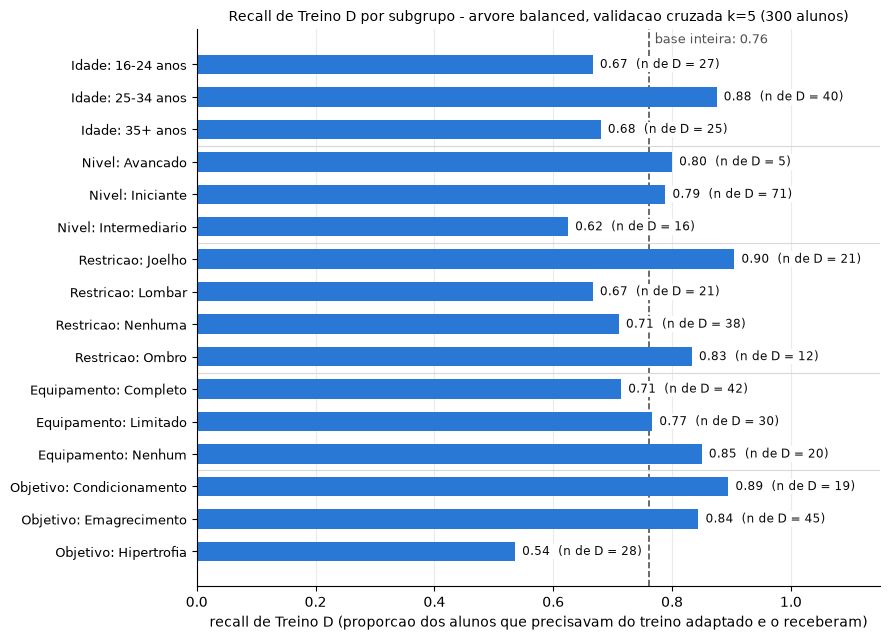

In [16]:
# Figura: recall de Treino D por subgrupo (modelo final, validacao cruzada)
geral = recall_D(y, df['previsto'])
plot = sub.iloc[::-1].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 6.5))
ax.axvline(geral, color='#52514e', ls='--', lw=1.2, zorder=1)
ax.barh(range(len(plot)), plot['recall_D'], color='#2a78d6', height=0.6, zorder=2)
ax.text(geral + 0.01, len(plot) - 0.35, f'base inteira: {geral:.2f}', color='#52514e', fontsize=9)
for i, r in plot.iterrows():
    ax.text(r['recall_D'] + 0.012, i, f"{r['recall_D']:.2f}  (n de D = {r['alunos_D']})", va='center', fontsize=8.5,
            color='#0b0b0b', zorder=3, bbox=dict(facecolor='white', edgecolor='none', pad=1))
nome_var = {'faixa_idade': 'Idade', 'nivel_experiencia': 'Nivel', 'restricao': 'Restricao',
            'equipamento_disponivel': 'Equipamento', 'objetivo': 'Objetivo'}
ax.set_yticks(range(len(plot)))
ax.set_yticklabels([f"{nome_var[r['variavel']]}: {r['subgrupo']}" for _, r in plot.iterrows()], fontsize=9)
for y_sep in [2.5, 5.5, 9.5, 12.5]:
    ax.axhline(y_sep, color='#d9d8d4', lw=0.8)
ax.set_xlim(0, 1.15)
ax.set_xlabel('recall de Treino D (proporcao dos alunos que precisavam do treino adaptado e o receberam)')
ax.set_title('Recall de Treino D por subgrupo - arvore balanced, validacao cruzada k=5 (300 alunos)', fontsize=10)
for s in ['top', 'right']:
    ax.spines[s].set_visible(False)
ax.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.savefig('recall_D_subgrupo_atividade15.png', dpi=150, bbox_inches='tight')
plt.show()

**Leitura dos subgrupos.**

- **Idade:** recall de D de ~0,88 para 25-34 anos, contra ~0,67-0,68 para 16-24 e para 35+. **A idade não aparece em nenhum ponto da regra de geração.** Na base, a idade não deveria fazer diferença nenhuma no treino, e mesmo assim os mais jovens e os mais velhos são atendidos pior.
- **Restrição lombar:** pior subgrupo do projeto. Acurácia ~0,65 e erro real ~26%, contra ~5% de quem não tem restrição.
- **Hipertrofia:** recall de D ~0,54. É a exceção "iniciante com até 2 dias" da seção 6.
- **Sem equipamento:** recall de D 0,85, bom, mas 3 alunos sem nenhum equipamento ainda recebem um treino que exige equipamento. A regra dura da seção 8 elimina esse erro.

### Verificação de proxy: idade

Idade é um atributo sensível: decidir o acesso a um serviço pela idade é discriminação etária. Ela entra no modelo como feature, mas a regra que define o treino correto não a usa. Então toda decisão que a árvore toma com base na idade é um **atalho espúrio** (já visto na Atividade 10) que distribui erro de forma desigual por faixa etária. Teste direto: remover a idade e comparar nos mesmos 50 folds.

In [17]:
X_sem_idade = X.drop(columns=['idade'])
linhas = []
for nome in ['Arvore original (max_depth=5)', 'Arvore balanced (modelo final)']:
    m = modelos[nome]
    m.fit(X, y)
    nos_idade = export_text(m, feature_names=list(X.columns)).count('idade <=')
    imp_idade = pd.Series(m.feature_importances_, X.columns)['idade']
    com = cross_validate(m, X, y, cv=rk, scoring=SCORING)
    sem = cross_validate(m, X_sem_idade, y, cv=rk, scoring=SCORING)
    d = sem['test_acc'] - com['test_acc']
    linhas.append({'modelo': nome, 'nos que usam idade': nos_idade, 'importancia da idade': imp_idade,
                   'acuracia com idade': com['test_acc'].mean(), 'acuracia sem idade': sem['test_acc'].mean(),
                   'sem idade ganha (folds)': (d > 0).sum(), 'sem idade perde (folds)': (d < 0).sum(),
                   'recall D com idade': com['test_recD'].mean(), 'recall D sem idade': sem['test_recD'].mean()})
pd.DataFrame(linhas).set_index('modelo').T.round(4)

modelo,Arvore original (max_depth=5),Arvore balanced (modelo final)
nos que usam idade,6.0000,6.0000
importancia da idade,0.0249,0.0292
acuracia com idade,0.8260,0.8350
acuracia sem idade,0.8503,0.8440
sem idade ganha (folds),36.0000,22.0000
sem idade perde (folds),7.0000,8.0000
recall D com idade,0.7676,0.7602
recall D sem idade,0.8187,0.7819


In [18]:
df['previsto_sem_idade'] = cross_val_predict(final, X_sem_idade, y, cv=5)
comp = pd.DataFrame(por_subgrupo('faixa_idade'))[['subgrupo', 'alunos_D', 'recall_D', 'acuracia']]
comp2 = pd.DataFrame(por_subgrupo('faixa_idade', 'previsto_sem_idade'))[['recall_D', 'acuracia']]
comp[['recall_D sem idade', 'acuracia sem idade']] = comp2.values
print('Idade media por treino recomendado (sem relacao real):', df.groupby('treino_recomendado')['idade'].mean().round(1).to_dict())
comp.round(3)

Idade media por treino recomendado (sem relacao real): {'Treino A': 29.4, 'Treino B': 27.7, 'Treino C': 30.1, 'Treino D': 29.4}


,subgrupo,alunos_D,recall_D,acuracia,recall_D sem idade,acuracia sem idade
0,16-24 anos,27,0.667,0.809,0.741,0.831
1,25-34 anos,40,0.875,0.877,0.875,0.885
2,35+ anos,25,0.680,0.815,0.720,0.827


**Resposta à pergunta da Atividade 11 (balancear muda o uso da idade?).** Não. A árvore balanced continua usando idade em 6 nós, com importância parecida com a da original (~0,03). O balanceamento só muda o peso de cada exemplo por classe. A idade é escolhida porque, numa base de 300 alunos com 8% de rótulos trocados ao acaso, sempre existe algum corte de idade que, por coincidência, separa alguns rótulos ruidosos no treino. Isso é ruído sendo memorizado, e trocar o peso das classes não elimina esse ruído.

**Resultado da verificação de proxy.** Sem a idade, o modelo fica **igual ou melhor**: a acurácia sobe nas duas árvores, e na original o modelo sem idade ganha em 36 dos 50 folds. O recall de D também sobe, e a diferença entre faixas etárias diminui. A idade não traz informação útil e ainda espalha o erro de forma desigual entre as faixas etárias. **Decisão: remover a idade das features do modelo final da AS.**

Outros atributos sensíveis: `restricao_fisica` é um **dado de saúde** (dado pessoal sensível pela LGPD, art. 5º, II). Ela é necessária para a finalidade (segurança do treino), mas exige consentimento explícito e não pode ser usada para outra coisa. A base **não tem gênero, renda ou etnia**, então não dá para auditar o desempenho por esses grupos. Isso é uma lacuna da auditoria, não uma prova de ausência de viés.

## 10. Configuração proposta para a AS (resumo das decisões medidas)

Árvore balanced **sem idade** + **regra de segurança** (restrição + iniciante, ou sem equipamento → Treino D), medida fora da amostra e comparada com o modelo final atual e com o baseline.

In [19]:
p_base = cross_val_predict(modelos['Baseline (most_frequent)'], X, y, cv=5)
regra_final = regras['restricao + iniciante  OU  sem equipamento']
p_proposta = df['previsto_sem_idade'].where(~regra_final, 'Treino D')
resumo = pd.DataFrame([
    {'configuracao': 'Baseline (sempre Treino D)', 'acuracia': accuracy_score(y, p_base), 'recall_D': recall_D(y, p_base), 'precisao_D': precisao_D(y, p_base), 'falsos_neg_D': ((y == 'Treino D') & (p_base != 'Treino D')).sum()},
    {'configuracao': 'Arvore balanced (modelo final atual)', 'acuracia': accuracy_score(y, df['previsto']), 'recall_D': recall_D(y, df['previsto']), 'precisao_D': precisao_D(y, df['previsto']), 'falsos_neg_D': ((y == 'Treino D') & (df['previsto'] != 'Treino D')).sum()},
    {'configuracao': 'Balanced sem idade', 'acuracia': accuracy_score(y, df['previsto_sem_idade']), 'recall_D': recall_D(y, df['previsto_sem_idade']), 'precisao_D': precisao_D(y, df['previsto_sem_idade']), 'falsos_neg_D': ((y == 'Treino D') & (df['previsto_sem_idade'] != 'Treino D')).sum()},
    {'configuracao': 'Balanced sem idade + regra de seguranca', 'acuracia': accuracy_score(y, p_proposta), 'recall_D': recall_D(y, p_proposta), 'precisao_D': precisao_D(y, p_proposta), 'falsos_neg_D': ((y == 'Treino D') & (p_proposta != 'Treino D')).sum()},
]).set_index('configuracao')
print('Alunos que precisavam de Treino D na base:', (y == 'Treino D').sum())
resumo.round(4)

Alunos que precisavam de Treino D na base: 92


,acuracia,recall_D,precisao_D,falsos_neg_D
configuracao,,,,
Baseline (sempre Treino D),0.3067,1.0000,0.3067,0
Arvore balanced (modelo final atual),0.8400,0.7609,0.8434,22
Balanced sem idade,0.8533,0.7935,0.8488,19
Balanced sem idade + regra de seguranca,0.8833,0.8913,0.8632,10


**Leitura.** Cada passo é uma decisão medida, e não um palpite. Tirar a idade remove um atalho espúrio, e a regra de segurança cobre os casos em que o modelo não tem evidência suficiente. Os números da última linha são **otimistas** pelo mesmo motivo da seção 8 (a regra coincide com a regra de geração). Na AS, eles serão apresentados como "o melhor que o modelo pode fazer nesta base sintética", não como o desempenho esperado com alunos reais.

O relatório crítico completo, que interpreta estes números, está em `entregas/Atividade15_ViniciusCasagrande.md`.